In [1]:
import numpy as np
import pickle

from particle_filter.filtering_algorithms.kalman_filter import KalmanFilter

from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel

from particle_filter.simulations import system_simulation

from particle_filter.plots.plot_results import plot_results

# PENDULO
Un péndulo (sin control) suele modelarse en espacio de estados como:

$$
x = 
\begin{bmatrix}
\theta \\
\omega
\end{bmatrix}
$$

con 
- $\theta$: ángulo
- $\omega$: velocidad angular

Ecuación continua:

$$
\dot{\theta} = \omega \\
\dot{\omega} = -\frac{g}{L}sin(\theta)
$$

### Discretización
Dado que se trabaja con el tiempo discreto, se necesita realizar una aproximación numérica. En este caso se ha tomado Euler.

La idea es aproximar las derivadas como:

$$
x´(t)\approx \frac{x_{n+1} - x_n}{\Delta t} 
$$

y despejando:

$$
x_{n+1} = x_n + \Delta t \;x´(t_n)
$$

Por lo tanto, tras la discretización, las ecuacciones del péndulo quedan:

$$
\theta_{n+1} = \theta_{n} + \Delta t\;w_n \\
w_{n+1} = w_n - \Delta t\; \frac{g}{L}\;sin(\theta_n)
$$

Depende mucho del valor de $\Delta_t$ y no conservar la energía provocando que el péndulo gane energía artificial (oscilaciones cada vez más grandes) o perder energía (amortiguamiento artificial).

### Observación

En este ejemplo se tiene el caso en el que solamente se mide el ángulo:

$$
y_t = \theta_t + v_t
$$

### Ecuación en espacio de estados

Finalmente, el modelo en espacio de estados tiene la siguiente forma

- Vector estado

$$
x_k = \begin{bmatrix}
\theta_k \\
\omega_k
\end{bmatrix}
$$

- Modelo dinámico 

$$
x_{k+1} = \begin{bmatrix}
\theta_k + \omega_k\; \Delta_t \\
\omega_k - \frac{g}{L}\;sin(\theta_k)\;\Delta_t
\end{bmatrix}
+ w_k
$$

- Modelo de medición

$$
y_k = \begin{bmatrix} 1 &0 \end{bmatrix} x_k + v_k
$$

con 

$$
w_k \sim \mathcal{N}(0, Q)\quad \quad v_k \sim \mathcal{N}(0, R)\\\\[2ex]

Q = \begin{bmatrix}

10^{-4} &0\\
0 &10^{-3}
\end{bmatrix}

\quad \quad

R = \begin{bmatrix} 10^{-2} \end{bmatrix}
$$

### Aproximación ángulos pequeños

Para poder linealizar el sistema y poder aplicar el filtro de Kalman, se realiza la aproximación para ángulos pequeños

$$
sin(\theta) \approx \theta
$$

Entonces

$$
\dot{\theta}= w \quad\quad\quad \dot{w} = -\frac{g}{L}\theta
$$

La aproximación de Euler

$$
A =
\begin{bmatrix}
1 &dt\\
-\frac{g}{L}\cdot dt &1
\end{bmatrix}
$$

Por lo tanto, el modelo en espacio de estados para el caso del filtro de Kalman es:

- Vector estado

$$
x_k = \begin{bmatrix}
\theta_k \\
\omega_k
\end{bmatrix}
$$

- Modelo dinámico 

$$
x_{k+1} = \begin{bmatrix}
\theta_k + \omega_k\; \Delta_t \\
\omega_k - \frac{g}{L}\;\theta_k\;\Delta_t
\end{bmatrix}
+ w_k
$$

- Modelo de medición

$$
y_k = \begin{bmatrix} 1 &0 \end{bmatrix} x_k + v_k
$$

con 

$$
w_k \sim \mathcal{N}(0, Q)\quad \quad v_k \sim \mathcal{N}(0, R)\\\\[2ex]

Q = \begin{bmatrix}

10^{-4} &0\\
0 &10^{-3}
\end{bmatrix}

\quad \quad

R = \begin{bmatrix} 10^{-2} \end{bmatrix}
$$

A continuación, se van a ejecutar el filtado con el Kalman Filter, Bootstrap Particle Filter y Auxiliary Particle Filter (estos dos últimos con re-muestreo) para diferentes ángulos iniciales.

Para cada caso, en los modelos de filtrado se considera que se conoce el estado inicial con el ángulo de cada caso y con velocidad angular nula:

$$
x_0 = \begin{bmatrix}
\theta_0 \\
0
\end{bmatrix}
$$

y la incertidumbre inicial se elige pequeña.

$$
P_0 = \begin{bmatrix}
\sigma_\theta^2 &0\\
0 &\sigma_\omega^2
\end{bmatrix}
$$

con 

$$
\sigma_\theta = 1º \quad\quad\quad \sigma_\omega = 0.05\; rad/s
$$

Así el filtro de Kalman se inicializa con media $x_0$ y covarianza $P_0$. 

El filtro de partículas (con pesos uniformes) genera las partículas iniciles según 

$$
x_0^{(i)} \sim \mathcal{N}(x_0, P_0)\quad i=1,...,N
$$

In [3]:
P0 = np.diag([
    np.deg2rad(1)**2,
    0.05**2
])

- Definición parámetros

In [4]:
# Parámetros péndulo
g = 9.81
L = 1.0

# Paso de tiempo (discretización)
dt = 0.01

- Definición funciones transición y observación (filtro de Partículas)

In [5]:
# Definición función de transición
def f(x):
    theta, omega = x

    omega_dot = -(g / L) * np.sin(theta)

    theta_next = theta + omega * dt
    omega_next = omega + omega_dot * dt

    theta_next = (theta_next + np.pi) % (2*np.pi) - np.pi

    return np.array([theta_next, omega_next])


# Definición función de medición 
def h(x):
    theta, _ = x

    return np.array([theta])

- Definición matrices de estado (filtro de Kalman)

In [6]:
# Matriz transición
A = np.array([
    [1, dt],
    [-(g/L)*dt, 1]
])

# Matriz obsevación
H = np.array([[1, 0]])

El estado real (denominado $x_{true}$) se simula sin ruido de transición y los resultados del filtrado se compararán con este. 

- Ruidos de transición y observación

In [7]:
# Definición ruido simulación
Q_sim = np.diag([0.0, 0.0])

noise_transition_simulation = GaussianNoise(Q_sim)
transition_simulation = AdditiveTransitionModel(f, noise_transition_simulation)

In [8]:
# Definición de ruidos 
Q = np.diag([1e-4, 1e-3]) #ruido de proceso
R = np.array([[1e-2]]) #ruido medicion

noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation)


### Caso 1: Ángulo inicial 5º

In [9]:
# Simulación
T = 500
x0 = np.array([
    np.deg2rad(5), # 5 grados iniciales
    0.0            # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition_simulation, observation, x0, T)

In [10]:
# Inicializacion modelos
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf.initialize(mean=x0, cov=P0)

apf = AuxiliaryParticleFilter(
    N=1000, 
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=x0, cov=P0)

kf = KalmanFilter(A, H, Q, R, x0, P0)

In [11]:
# Ejecucion filtrados
est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N)/2)
print("Bootstrap Particle Filter finalizado")

est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N)/2)
print("Auxiliary Particle Filter finalizado")

est_kf = kf.run_filter(y_obs)
print("Kalman Filter finalizado")

Bootstrap Particle Filter finalizado
Auxiliary Particle Filter finalizado
Kalman Filter finalizado


In [12]:
results = {
    "x_true": x_true,
    "y_obs": y_obs,
    "results_bpf": est_bpf,
    "results_apf": est_apf,
    "results_kf": est_kf
}

with open("results_5.pkl", "wb") as file:
    pickle.dump(results, file)

In [8]:
with open("results_5.pkl", "rb") as file:
    results = pickle.load(file)

x_true = results["x_true"]
y_obs = results["y_obs"]
est_bpf = results["results_bpf"]
est_apf = results["results_apf"]
est_kf = results["results_kf"]

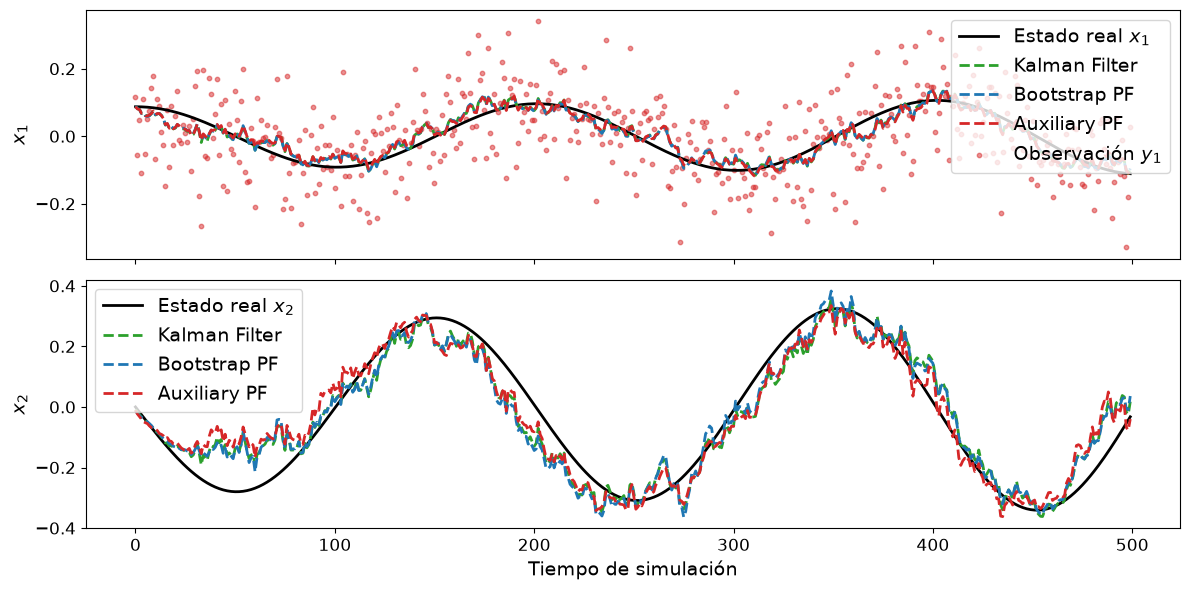

In [9]:
# Plot resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"],
}

plot_results(x_true, y_obs, estimates, x_title="Tiempo de simulación", plot_title="Comparación estado estimado")

In [15]:
from particle_filter.performance_metrics import RMSE

# Resultados estadísticos
print(f"RMSE(posicion) Bootstrap PF: {RMSE(x_true[:,0], est_bpf["estimates"][:,0])}")
print(f"RMSE(posicion) Auxiliary PF: {RMSE(x_true[:,0], est_apf["estimates"][:,0])}")
print(f"RMSE(posicion) Kalman Filter: {RMSE(x_true[:,0], est_kf["estimates"][:,0])}")
print("")
print(f"RMSE(velocidad) Bootstrap PF: {RMSE(x_true[:,1], est_bpf["estimates"][:,1])}")
print(f"RMSE(velocidad) Auxiliary PF: {RMSE(x_true[:,1], est_apf["estimates"][:,1])}")
print(f"RMSE(velocidad) Kalman Filter: {RMSE(x_true[:,1], est_kf["estimates"][:,1])}")
print("")
print(f"RMSE Total Bootstrap PF: {RMSE(x_true, est_bpf["estimates"])}")
print(f"RMSE Total Auxiliary PF: {RMSE(x_true, est_apf["estimates"])}")
print(f"RMSE Total Kalman Filter: {RMSE(x_true, est_kf["estimates"])}")
print("")
print(f"Logverosimilitud Bootstrap PF: {est_bpf["log_likelihood"]}")
print(f"Logverosimilitud Auxiliary PF: {est_apf["log_likelihood"]}")
print(f"Logverosimilitud Kalman Filter: {est_kf["loglikelihood"]}")
print("")
print(f"Tiempo ejecucion Bootstrap PF: {est_bpf["execution_time"]}")
print(f"Tiempo ejecucion Auxiliary PF: {est_apf["execution_time"]}")
print(f"Tiempo ejecucion Kalman Filter: {est_kf["execution_time"]}")

RMSE(posicion) Bootstrap PF: 0.024891567757200746
RMSE(posicion) Auxiliary PF: 0.025275686677855208
RMSE(posicion) Kalman Filter: 0.025236231364391907

RMSE(velocidad) Bootstrap PF: 0.07317025452449585
RMSE(velocidad) Auxiliary PF: 0.07553511127118981
RMSE(velocidad) Kalman Filter: 0.07244814476947585

RMSE Total Bootstrap PF: 0.054651058052844786
RMSE Total Auxiliary PF: 0.05632234623925096
RMSE Total Kalman Filter: 0.05424758544864485

Logverosimilitud Bootstrap PF: 416.86920838695505
Logverosimilitud Auxiliary PF: 417.43730654625745
Logverosimilitud Kalman Filter: 416.36100269480187

Tiempo ejecucion Bootstrap PF: 48.9118926001247
Tiempo ejecucion Auxiliary PF: 118.18041120003909
Tiempo ejecucion Kalman Filter: 0.0332549000158906


### Caso 2: Ángulo inicial 15º

In [16]:
# Simulación
T = 500
x0 = np.array([
    np.deg2rad(15), # 5 grados iniciales
    0.0            # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition_simulation, observation, x0, T)

In [17]:
# Inicializacion modelos
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf.initialize(mean=x0, cov=P0)

apf = AuxiliaryParticleFilter(
    N=1000, 
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=x0, cov=P0)

kf = KalmanFilter(A, H, Q, R, x0, P0)

In [18]:
# Ejecucion filtrados
est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N)/2)
print("Bootstrap Particle Filter finalizado")

est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N)/2)
print("Auxiliary Particle Filter finalizado")

est_kf = kf.run_filter(y_obs)
print("Kalman Filter finalizado")

Bootstrap Particle Filter finalizado
Auxiliary Particle Filter finalizado
Kalman Filter finalizado


In [19]:
results = {
    "x_true": x_true,
    "y_obs": y_obs,
    "results_bpf": est_bpf,
    "results_apf": est_apf,
    "results_kf": est_kf
}

with open("results_15.pkl", "wb") as file:
    pickle.dump(results, file)

In [10]:
with open("results_15.pkl", "rb") as file:
    results = pickle.load(file)

x_true = results["x_true"]
y_obs = results["y_obs"]
est_bpf = results["results_bpf"]
est_apf = results["results_apf"]
est_kf = results["results_kf"]

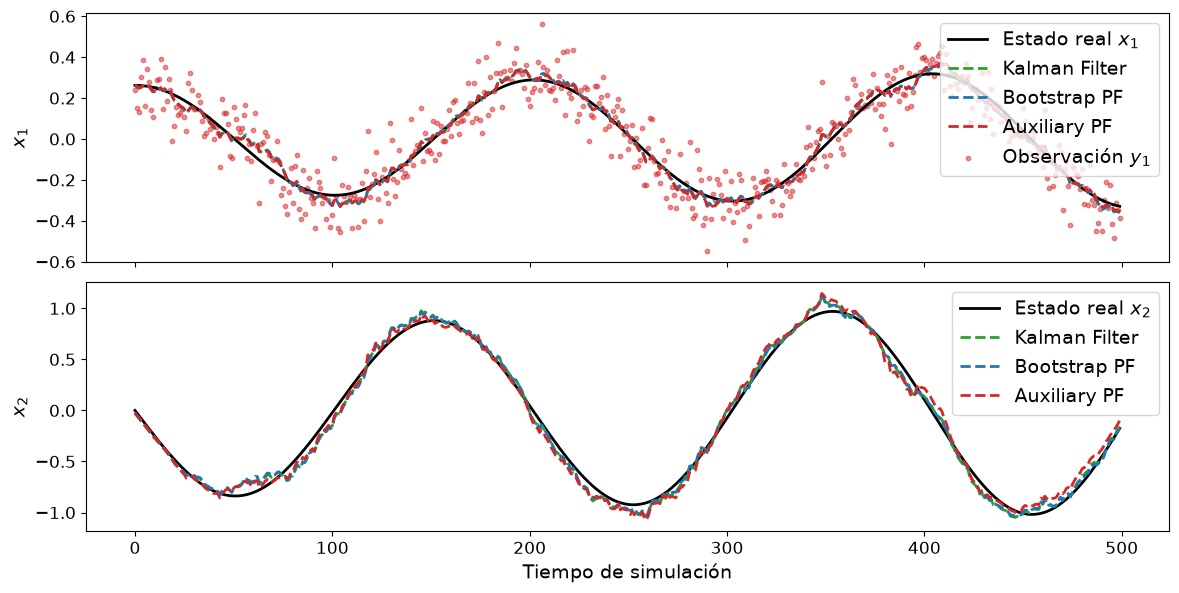

In [11]:
# Plot resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"],
}

plot_results(x_true, y_obs, estimates, x_title="Tiempo de simulación", plot_title="Comparacióne estado estimado")

In [22]:
# Resultados estadísticos
print(f"RMSE(posicion) Bootstrap PF: {RMSE(x_true[:,0], est_bpf["estimates"][:,0])}")
print(f"RMSE(posicion) Auxiliary PF: {RMSE(x_true[:,0], est_apf["estimates"][:,0])}")
print(f"RMSE(posicion) Kalman Filter: {RMSE(x_true[:,0], est_kf["estimates"][:,0])}")
print("")
print(f"RMSE(velocidad) Bootstrap PF: {RMSE(x_true[:,1], est_bpf["estimates"][:,1])}")
print(f"RMSE(velocidad) Auxiliary PF: {RMSE(x_true[:,1], est_apf["estimates"][:,1])}")
print(f"RMSE(velocidad) Kalman Filter: {RMSE(x_true[:,1], est_kf["estimates"][:,1])}")
print("")
print(f"RMSE Total Bootstrap PF: {RMSE(x_true, est_bpf["estimates"])}")
print(f"RMSE Total Auxiliary PF: {RMSE(x_true, est_apf["estimates"])}")
print(f"RMSE Total Kalman Filter: {RMSE(x_true, est_kf["estimates"])}")
print("")
print(f"Logverosimilitud Bootstrap PF: {est_bpf["log_likelihood"]}")
print(f"Logverosimilitud Auxiliary PF: {est_apf["log_likelihood"]}")
print(f"Logverosimilitud Kalman Filter: {est_kf["loglikelihood"]}")
print("")
print(f"Tiempo ejecucion Bootstrap PF: {est_bpf["execution_time"]}")
print(f"Tiempo ejecucion Auxiliary PF: {est_apf["execution_time"]}")
print(f"Tiempo ejecucion Kalman Filter: {est_kf["execution_time"]}")


RMSE(posicion) Bootstrap PF: 0.027322037409095647
RMSE(posicion) Auxiliary PF: 0.027350343946974366
RMSE(posicion) Kalman Filter: 0.027626361968244577

RMSE(velocidad) Bootstrap PF: 0.06088776865467588
RMSE(velocidad) Auxiliary PF: 0.07554169382965807
RMSE(velocidad) Kalman Filter: 0.06560019635452324

RMSE Total Bootstrap PF: 0.04719011601982641
RMSE Total Auxiliary PF: 0.05680928102287335
RMSE Total Kalman Filter: 0.050331906567069734

Logverosimilitud Bootstrap PF: 434.15949518045966
Logverosimilitud Auxiliary PF: 434.06799501502803
Logverosimilitud Kalman Filter: 434.33661500724685

Tiempo ejecucion Bootstrap PF: 50.3797303000465
Tiempo ejecucion Auxiliary PF: 105.26427109981887
Tiempo ejecucion Kalman Filter: 0.028918799944221973


### Caso 3: Ángulo inicial 45º

In [23]:
# Simulación
T = 500
x0 = np.array([
    np.deg2rad(45), # 5 grados iniciales
    0.0            # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition_simulation, observation, x0, T)

In [24]:
# Inicializacion modelos
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf.initialize(mean=x0, cov=P0)

apf = AuxiliaryParticleFilter(
    N=1000, 
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=x0, cov=P0)

kf = KalmanFilter(A, H, Q, R, x0, P0)

In [25]:
# Ejecucion filtrados
est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N)/2)
print("Bootstrap Particle Filter finalizado")

est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N)/2)
print("Auxiliary Particle Filter finalizado")

est_kf = kf.run_filter(y_obs)
print("Kalman Filter finalizado")

Bootstrap Particle Filter finalizado
Auxiliary Particle Filter finalizado
Kalman Filter finalizado


In [12]:
results = {
    "x_true": x_true,
    "y_obs": y_obs,
    "results_bpf": est_bpf,
    "results_apf": est_apf,
    "results_kf": est_kf
}

with open("results_45.pkl", "wb") as file:
    pickle.dump(results, file)

In [6]:
with open("results_45.pkl", "rb") as file:
    results = pickle.load(file)

x_true = results["x_true"]
y_obs = results["y_obs"]
est_bpf = results["results_bpf"]
est_apf = results["results_apf"]
est_kf = results["results_kf"]

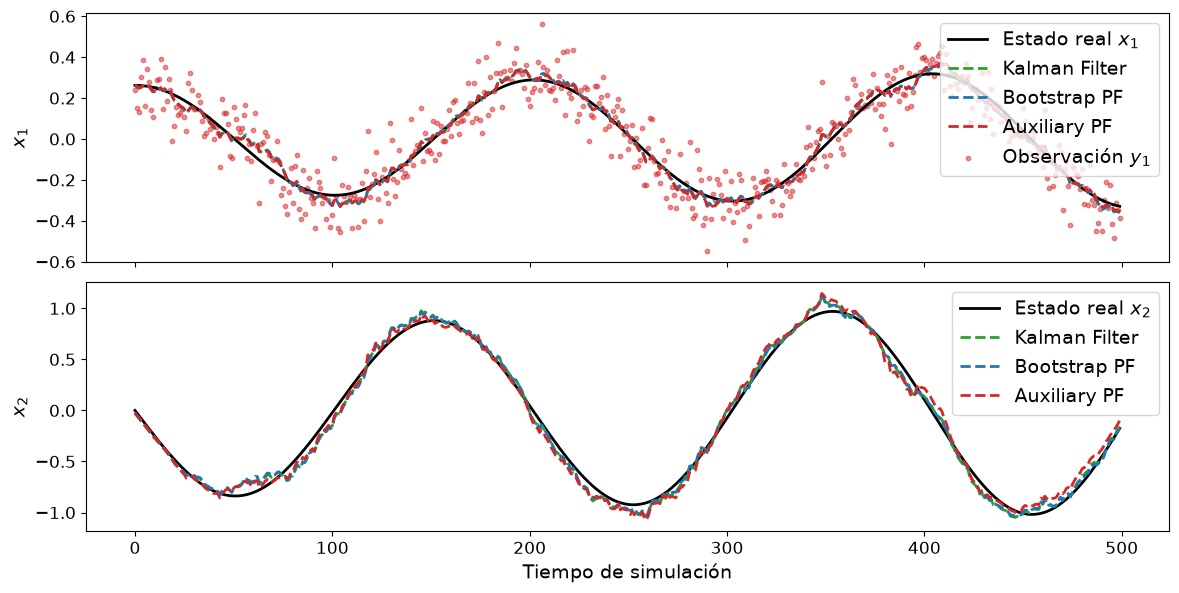

In [13]:
# Plot resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"],
}

plot_results(x_true, y_obs, estimates, x_title="Tiempo de simulación", plot_title="Comparacióne estado estimado")

In [29]:
# Resultados estadísticos
print(f"RMSE(posicion) Bootstrap PF: {RMSE(x_true[:,0], est_bpf["estimates"][:,0])}")
print(f"RMSE(posicion) Auxiliary PF: {RMSE(x_true[:,0], est_apf["estimates"][:,0])}")
print(f"RMSE(posicion) Kalman Filter: {RMSE(x_true[:,0], est_kf["estimates"][:,0])}")
print("")
print(f"RMSE(velocidad) Bootstrap PF: {RMSE(x_true[:,1], est_bpf["estimates"][:,1])}")
print(f"RMSE(velocidad) Auxiliary PF: {RMSE(x_true[:,1], est_apf["estimates"][:,1])}")
print(f"RMSE(velocidad) Kalman Filter: {RMSE(x_true[:,1], est_kf["estimates"][:,1])}")
print("")
print(f"RMSE Total Bootstrap PF: {RMSE(x_true, est_bpf["estimates"])}")
print(f"RMSE Total Auxiliary PF: {RMSE(x_true, est_apf["estimates"])}")
print(f"RMSE Total Kalman Filter: {RMSE(x_true, est_kf["estimates"])}")
print("")
print(f"Logverosimilitud Bootstrap PF: {est_bpf["log_likelihood"]}")
print(f"Logverosimilitud Auxiliary PF: {est_apf["log_likelihood"]}")
print(f"Logverosimilitud Kalman Filter: {est_kf["loglikelihood"]}")
print("")
print(f"Tiempo ejecucion Bootstrap PF: {est_bpf["execution_time"]}")
print(f"Tiempo ejecucion Auxiliary PF: {est_apf["execution_time"]}")
print(f"Tiempo ejecucion Kalman Filter: {est_kf["execution_time"]}")

RMSE(posicion) Bootstrap PF: 0.02333807390788306
RMSE(posicion) Auxiliary PF: 0.023149628352351605
RMSE(posicion) Kalman Filter: 0.026986545249007943

RMSE(velocidad) Bootstrap PF: 0.06200767052229495
RMSE(velocidad) Auxiliary PF: 0.06182337880368739
RMSE(velocidad) Kalman Filter: 0.17518299753963668

RMSE Total Bootstrap PF: 0.04684878278744976
RMSE Total Auxiliary PF: 0.04667994997617406
RMSE Total Kalman Filter: 0.12533426556901567

Logverosimilitud Bootstrap PF: 426.84811221274117
Logverosimilitud Auxiliary PF: 426.03740352032855
Logverosimilitud Kalman Filter: 422.66672170211325

Tiempo ejecucion Bootstrap PF: 48.035341599956155
Tiempo ejecucion Auxiliary PF: 125.44593569985591
Tiempo ejecucion Kalman Filter: 0.020405299961566925


### Caso 4: Ángulo 90º

In [30]:
# Simulación
T = 500
x0 = np.array([
    np.deg2rad(90), # 5 grados iniciales
    0.0            # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition_simulation, observation, x0, T)

In [31]:
# Inicializacion modelos
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf.initialize(mean=x0, cov=P0)

apf = AuxiliaryParticleFilter(
    N=1000, 
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=x0, cov=P0)

kf = KalmanFilter(A, H, Q, R, x0, P0)

In [32]:
# Ejecucion filtrados
est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N)/2)
print("Bootstrap Particle Filter finalizado")

est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N)/2)
print("Auxiliary Particle Filter finalizado")

est_kf = kf.run_filter(y_obs)
print("Kalman Filter finalizado")

Bootstrap Particle Filter finalizado
Auxiliary Particle Filter finalizado
Kalman Filter finalizado


In [33]:
results = {
    "x_true": x_true,
    "y_obs": y_obs,
    "results_bpf": est_bpf,
    "results_apf": est_apf,
    "results_kf": est_kf
}

with open("results_90.pkl", "wb") as file:
    pickle.dump(results, file)

In [14]:
with open("results_90.pkl", "rb") as file:
    results = pickle.load(file)

x_true = results["x_true"]
y_obs = results["y_obs"]
est_bpf = results["results_bpf"]
est_apf = results["results_apf"]
est_kf = results["results_kf"]

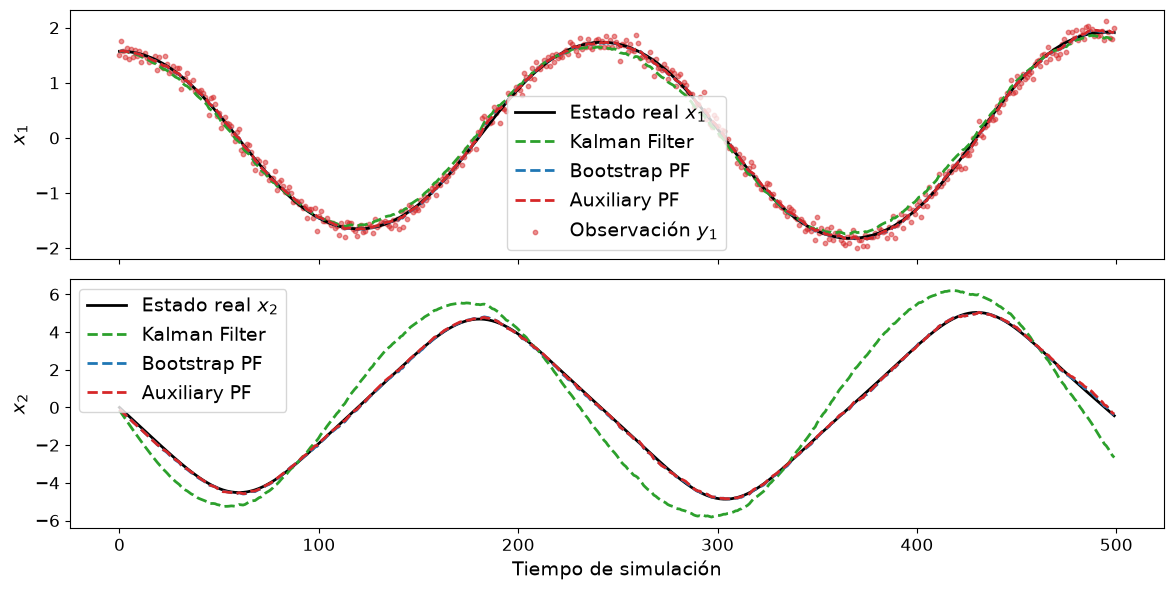

In [16]:
# Plot resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"],
}

plot_results(x_true, y_obs, estimates, x_title="Tiempo de simulación", plot_title="Comparacióne estado estimado")

In [35]:
# Resultados estadísticos
print(f"RMSE(posicion) Bootstrap PF: {RMSE(x_true[:,0], est_bpf["estimates"][:,0])}")
print(f"RMSE(posicion) Auxiliary PF: {RMSE(x_true[:,0], est_apf["estimates"][:,0])}")
print(f"RMSE(posicion) Kalman Filter: {RMSE(x_true[:,0], est_kf["estimates"][:,0])}")
print("")
print(f"RMSE(velocidad) Bootstrap PF: {RMSE(x_true[:,1], est_bpf["estimates"][:,1])}")
print(f"RMSE(velocidad) Auxiliary PF: {RMSE(x_true[:,1], est_apf["estimates"][:,1])}")
print(f"RMSE(velocidad) Kalman Filter: {RMSE(x_true[:,1], est_kf["estimates"][:,1])}")
print("")
print(f"RMSE Total Bootstrap PF: {RMSE(x_true, est_bpf["estimates"])}")
print(f"RMSE Total Auxiliary PF: {RMSE(x_true, est_apf["estimates"])}")
print(f"RMSE Total Kalman Filter: {RMSE(x_true, est_kf["estimates"])}")
print("")
print(f"Logverosimilitud Bootstrap PF: {est_bpf["log_likelihood"]}")
print(f"Logverosimilitud Auxiliary PF: {est_apf["log_likelihood"]}")
print(f"Logverosimilitud Kalman Filter: {est_kf["loglikelihood"]}")
print("")
print(f"Tiempo ejecucion Bootstrap PF: {est_bpf["execution_time"]}")
print(f"Tiempo ejecucion Auxiliary PF: {est_apf["execution_time"]}")
print(f"Tiempo ejecucion Kalman Filter: {est_kf["execution_time"]}")

RMSE(posicion) Bootstrap PF: 0.023593290475048982
RMSE(posicion) Auxiliary PF: 0.023979725764805875
RMSE(posicion) Kalman Filter: 0.09034431215400487

RMSE(velocidad) Bootstrap PF: 0.06021665920651518
RMSE(velocidad) Auxiliary PF: 0.06116860849268236
RMSE(velocidad) Kalman Filter: 1.21478078015707

RMSE Total Bootstrap PF: 0.04573122238380265
RMSE Total Auxiliary PF: 0.046457646909235234
RMSE Total Kalman Filter: 0.8613519717797133

Logverosimilitud Bootstrap PF: 419.5215641730902
Logverosimilitud Auxiliary PF: 420.13346531154696
Logverosimilitud Kalman Filter: 186.32224854130777

Tiempo ejecucion Bootstrap PF: 49.893107400042936
Tiempo ejecucion Auxiliary PF: 106.68872059998102
Tiempo ejecucion Kalman Filter: 0.030217699939385056


### Caso 5: Ángulo 120º

In [36]:
# Simulación
T = 500
x0 = np.array([
    np.deg2rad(120), # 5 grados iniciales
    0.0            # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition_simulation, observation, x0, T)

In [37]:
# Inicializacion modelos
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf.initialize(mean=x0, cov=P0)

apf = AuxiliaryParticleFilter(
    N=1000, 
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=x0, cov=P0)

kf = KalmanFilter(A, H, Q, R, x0, P0)

In [38]:
# Ejecucion filtrados
est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N)/2)
print("Bootstrap Particle Filter finalizado")

est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N)/2)
print("Auxiliary Particle Filter finalizado")

est_kf = kf.run_filter(y_obs)
print("Kalman Filter finalizado")

Bootstrap Particle Filter finalizado
Auxiliary Particle Filter finalizado
Kalman Filter finalizado


In [17]:
with open("results_120.pkl", "rb") as file:
    results = pickle.load(file)

x_true = results["x_true"]
y_obs = results["y_obs"]
est_bpf = results["results_bpf"]
est_apf = results["results_apf"]
est_kf = results["results_kf"]

In [18]:
results = {
    "x_true": x_true,
    "y_obs": y_obs,
    "results_bpf": est_bpf,
    "results_apf": est_apf,
    "results_kf": est_kf
}

with open("results_120.pkl", "wb") as file:
    pickle.dump(results, file)

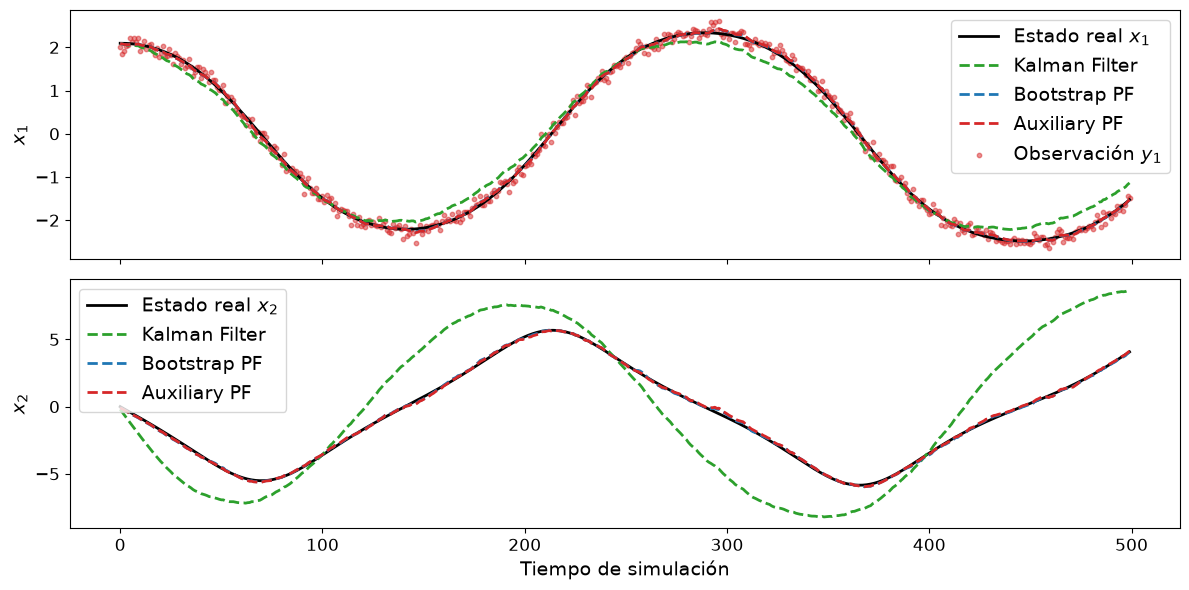

In [19]:
# Plot resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"],
}

plot_results(x_true, y_obs, estimates, x_title="Tiempo de simulación", plot_title="Comparacióne estado estimado")

In [41]:
# Resultados estadísticos
print(f"RMSE(posicion) Bootstrap PF: {RMSE(x_true[:,0], est_bpf["estimates"][:,0])}")
print(f"RMSE(posicion) Auxiliary PF: {RMSE(x_true[:,0], est_apf["estimates"][:,0])}")
print(f"RMSE(posicion) Kalman Filter: {RMSE(x_true[:,0], est_kf["estimates"][:,0])}")
print("")
print(f"RMSE(velocidad) Bootstrap PF: {RMSE(x_true[:,1], est_bpf["estimates"][:,1])}")
print(f"RMSE(velocidad) Auxiliary PF: {RMSE(x_true[:,1], est_apf["estimates"][:,1])}")
print(f"RMSE(velocidad) Kalman Filter: {RMSE(x_true[:,1], est_kf["estimates"][:,1])}")
print("")
print(f"RMSE Total Bootstrap PF: {RMSE(x_true, est_bpf["estimates"])}")
print(f"RMSE Total Auxiliary PF: {RMSE(x_true, est_apf["estimates"])}")
print(f"RMSE Total Kalman Filter: {RMSE(x_true, est_kf["estimates"])}")
print("")
print(f"Logverosimilitud Bootstrap PF: {est_bpf["log_likelihood"]}")
print(f"Logverosimilitud Auxiliary PF: {est_apf["log_likelihood"]}")
print(f"Logverosimilitud Kalman Filter: {est_kf["loglikelihood"]}")
print("")
print(f"Tiempo ejecucion Bootstrap PF: {est_bpf["execution_time"]}")
print(f"Tiempo ejecucion Auxiliary PF: {est_apf["execution_time"]}")
print(f"Tiempo ejecucion Kalman Filter: {est_kf["execution_time"]}")

RMSE(posicion) Bootstrap PF: 0.030647641110696972
RMSE(posicion) Auxiliary PF: 0.03187991519636024
RMSE(posicion) Kalman Filter: 0.22545463057600532

RMSE(velocidad) Bootstrap PF: 0.08441761233550038
RMSE(velocidad) Auxiliary PF: 0.09482205033635567
RMSE(velocidad) Kalman Filter: 3.0753494591331436

RMSE Total Bootstrap PF: 0.06350437456615453
RMSE Total Auxiliary PF: 0.07073736715102384
RMSE Total Kalman Filter: 2.1804362047809014

Logverosimilitud Bootstrap PF: 408.1216830469575
Logverosimilitud Auxiliary PF: 408.08343617020194
Logverosimilitud Kalman Filter: -1081.9546057526777

Tiempo ejecucion Bootstrap PF: 46.742431099992245
Tiempo ejecucion Auxiliary PF: 105.99154850002378
Tiempo ejecucion Kalman Filter: 0.03176969988271594


Para el primer caso, con un ángulo inicial de $5º$, la linealización del sistema del péndulo es lo susificientemente buena para que el filtro de Kalman obtenga el menor RMSE. Para un ágnulo de $15º$, el filtro de Kalman mantiene una buena aproximación. A partir de este momento, a medida que aumenta el ángulo inicial, el filtro de Kalman empieza a ser incapaz de seguir el estado del sistema. Para un ángulo de $45º$ gracias a las observaciones realizadas en el ángulo del péndulo, el filtro de Kalman aún puede mantener una buena aproximación para este parámetro. Sin embargo, la velocidad angular empieza a desviarse y el RMSE de este parámetro es considerablemente más alto que en el caso del Bootstrap PF o el Auiliary PF. Este comportamiento es análgo para un ángulo de $90º$ y para uno de $120º$ el filtro de Kalman obtiene resultados peores también para la posición del péndulo.

### Caso 5: Ángulo 180º

In [65]:
# Simulación
T = 500
x0 = np.array([
    np.deg2rad(180), # 5 grados iniciales
    0.0            # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition_simulation, observation, x0, T)

In [66]:
# Inicializacion modelos
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf.initialize(mean=x0, cov=P0)

apf = AuxiliaryParticleFilter(
    N=1000, 
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=x0, cov=P0)

kf = KalmanFilter(A, H, Q, R, x0, P0)

In [67]:
# Ejecucion filtrados
est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N)/2)
print("Bootstrap Particle Filter finalizado")

est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N)/2)
print("Auxiliary Particle Filter finalizado")

est_kf = kf.run_filter(y_obs)
print("Kalman Filter finalizado")

Bootstrap Particle Filter finalizado
Auxiliary Particle Filter finalizado
Kalman Filter finalizado


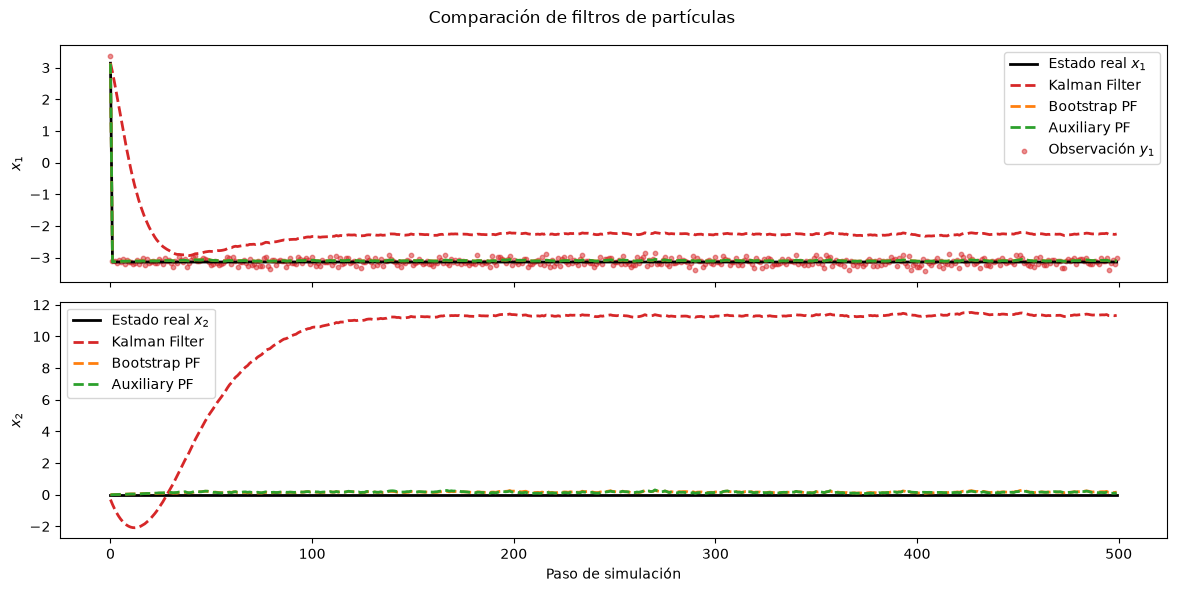

In [71]:
# Plot resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"],
}

plot_results(x_true, y_obs, estimates)

In [69]:
# Resultados estadísticos
print(f"RMSE(posicion) Bootstrap PF: {RMSE(x_true[:,0], est_bpf["estimates"][:,0])}")
print(f"RMSE(posicion) Auxiliary PF: {RMSE(x_true[:,0], est_apf["estimates"][:,0])}")
print(f"RMSE(posicion) Kalman Filter: {RMSE(x_true[:,0], est_kf["estimates"][:,0])}")
print("")
print(f"RMSE(velocidad) Bootstrap PF: {RMSE(x_true[:,1], est_bpf["estimates"][:,1])}")
print(f"RMSE(velocidad) Auxiliary PF: {RMSE(x_true[:,1], est_apf["estimates"][:,1])}")
print(f"RMSE(velocidad) Kalman Filter: {RMSE(x_true[:,1], est_kf["estimates"][:,1])}")
print("")
print(f"Logverosimilitud Bootstrap PF: {est_bpf["log_likelihood"]}")
print(f"Logverosimilitud Auxiliary PF: {est_apf["log_likelihood"]}")
print(f"Logverosimilitud Kalman Filter: {est_kf["loglikelihood"]}")
print("")
print(f"Tiempo ejecucion Bootstrap PF: {est_bpf["execution_time"]}")
print(f"Tiempo ejecucion Auxiliary PF: {est_apf["execution_time"]}")
print(f"Tiempo ejecucion Kalman Filter: {est_kf["execution_time"]}")

RMSE(posicion) Bootstrap PF: 0.04482391280295757
RMSE(posicion) Auxiliary PF: 0.04479260697623787
RMSE(posicion) Kalman Filter: 1.0677636449952839

RMSE(velocidad) Bootstrap PF: 0.16464368537112037
RMSE(velocidad) Auxiliary PF: 0.15920852176964118
RMSE(velocidad) Kalman Filter: 10.48607976765871

Logverosimilitud Bootstrap PF: 373.4892856701333
Logverosimilitud Auxiliary PF: 373.24513751269876
Logverosimilitud Kalman Filter: -30698.242024859883

Tiempo ejecucion Bootstrap PF: 42.74895089981146
Tiempo ejecucion Auxiliary PF: 98.27598930010572
Tiempo ejecucion Kalman Filter: 0.022525599924847484
